# Init:

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [78]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Daniel\\Desktop\\Thesis_Experiment\\QA_Datasets\\trivia_qa_train.json'

In [434]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Processing TriviaQA:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 78260/78260 [03:16<00:00, 398.08it/s]


Processing Natural Questions:


Classifying Answers: 100%|████████████████████████████████████████████████████| 106926/106926 [04:22<00:00, 407.29it/s]


Processing SQuAD:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 86821/86821 [03:09<00:00, 459.15it/s]


In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 209055 Q-A pairs out of original 272007(77%).


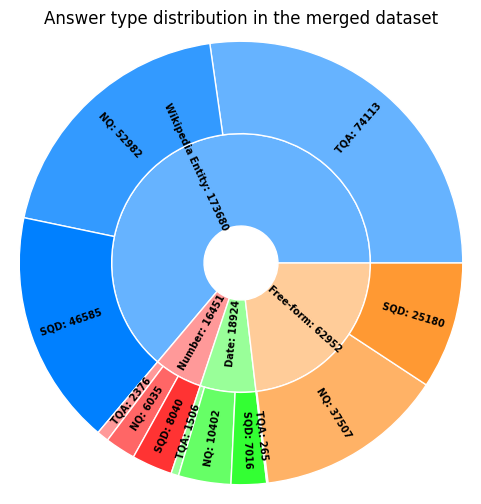

In [4]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [10]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: when did snow white and the seven dwarfs come out
Answer: 1937
Type: Date
Normalized: {'category': 'year', 'parsed_value': '1937'}
Question: What city in Rhode Island is famous for its many mansions built during the late 1800's?
Answer: Newport
Type: Wikipedia Entity
Normalized: Newport
Question: Erik the Red from Norway founded the first successful Norse settlement on Greenland, and then his son Leif continued the tradition of exploring west and landed where?
Answer: North America
Type: Wikipedia Entity
Normalized: North America
Question: What royal park shares a border with its neighbor, the park known as Kensington Gardens?
Answer: Hyde Park
Type: Wikipedia Entity
Normalized: Hyde Park
Question: How many earthquakes occurred on March 5, 2012?
Answer: twelve
Type: Number
Normalized: 12
Question: The Battle of Flodden took place in September 1513 in which English county?
Answer: Northumberland
Type: Wikipedia Entity
Normalized: Northumberland
Question: who won second place i

# 3. Group questions:

In [425]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

In [426]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.cluster_questions import *

In [427]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [428]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_numerical_values(num_data)
date_clusters = cluster_date_values(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)} with mean cluster size of: {np.mean([len(value) for value in ent_clusters.values()]):.2f}')
print(f'Numerical: {len(num_clusters)} with mean cluster size of: {np.mean([len(value) for value in num_clusters.values()]):.2f}')
print(f'Date & Time: {len(date_clusters)} with mean cluster size of: {np.mean([len(value) for value in date_clusters.values()]):.2f}')

Total candidate clusters:
Entities: 13337 with mean cluster size of: 6.90
Numerical: 18 with mean cluster size of: 649.94
Date & Time: 960 with mean cluster size of: 19.18


## 3.1 - Cluster and filter entity questions:

In [397]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
entity_reasoning_chains = await create_paths(ent_clusters, output_path=f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

Generating question embeddings: 100%|██████████████████████████████████████████████████| 45/45 [01:50<00:00,  2.45s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 13337/13337 [00:09<00:00, 1334.68it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████| 13337/13337 [00:00<00:00, 835765.14it/s]


In [214]:
# Load from folder:
entity_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

## 3.2 - Create numerical questions reasoning paths:

In [429]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
numerical_reasoning_chains = await create_paths(num_clusters, output_path=f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 6/6 [00:14<00:00,  2.42s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 18/18 [00:09<00:00,  1.82it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████████| 18/18 [00:00<00:00, 3923.99it/s]


In [398]:
# Load from folder:
numerical_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

## 3.3 - Create date & time questions reasoning paths:

In [47]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
date_reasoning_chains = await create_paths(date_clusters, output_path=f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:22<00:00,  2.53s/it]
Creating similarity graphs and filtering questions: 100%|███████████████████████████| 960/960 [00:01<00:00, 482.08it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████| 960/960 [00:00<00:00, 243104.02it/s]


In [399]:
# Load from folder:
date_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

## 3.4 - Show clusters distribution & display graph examples:

In [430]:
# Merge & save all clusters into one dataset:
reasoning_chains = list(np.concatenate([entity_reasoning_chains, numerical_reasoning_chains, date_reasoning_chains]))
output_path = f"{REPO_PATH}\data_files\\reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(reasoning_chains, out_file)

In [240]:
# Load from folder:
reasoning_chains = load_json(f"{REPO_PATH}\data_files\\reasoning_chains.json")

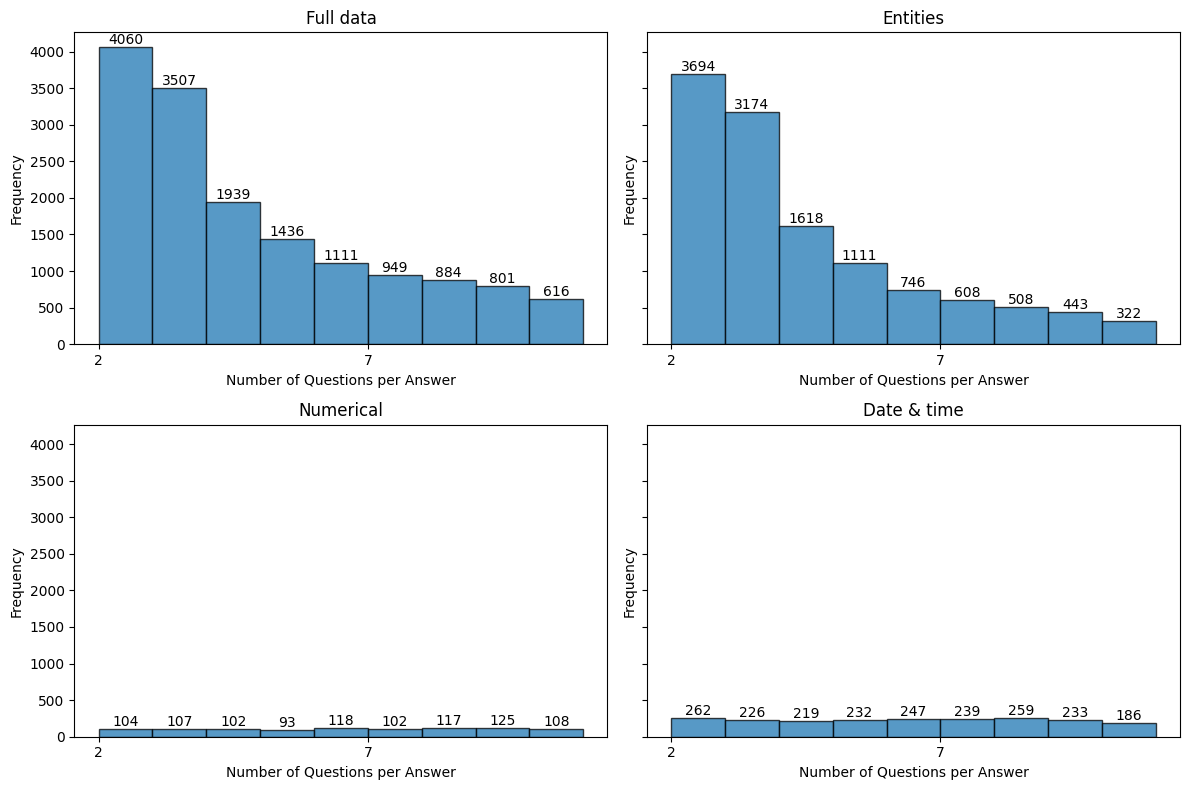

In [431]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution
plot_clusters_distribution({
    'Full data': reasoning_chains,
    'Entities': entity_reasoning_chains,
    'Numerical': numerical_reasoning_chains,
    'Date & time': date_reasoning_chains
})

In [432]:
from random import choice
# Plot random clusters:
print('=' * 50)
print('Entitity Cluster:')
print('=' * 50)
ent_sample = choice(entity_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Numerical Cluster:')
print('=' * 50)
ent_sample = choice(numerical_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Date & time Cluster:')
print('=' * 50)
ent_sample = choice(date_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)

Entitity Cluster:
Answer: Paul Jones
List of questions:
- A circular partner-swapping ballroom dance, named after a 1700s maritime leader, is the?
- Which harmonica-paying frontman of Manfred Man sang on their early hits and later became a successful radio presenter?
- Who presents the Radio 2 Rhythm & Blues Show at 7.00pm every Monday?
Numerical Cluster:
Answer: (11, 20)
List of questions:
- how many secret herbs and spices in kfc
- how many volumes of akatsuki no yona are there
- how many series are there in midsomer murders
- how many episodes are in season 3 of fuller house
- how many episodes of hap and leonard are there
- how many series of family guy is there
- how many times did al ahly win caf
- what age do you get your license in michigan
Date & time Cluster:
Answer: ['full_date', 2008]
List of questions:
- when did angus thongs and perfect snogging made
- when was the large hadron collider first turned on
- when did the corkscrew close at alton towers
- when did the new shap

Answer: Virat Kohli
Questions before filtering:
1. who has scored the most t20 runs for india
2. who is the indian cricket team captain 2018
3. who is the captain of indian cricket team right now
4. who won icc cricketer of the year award
5. who has been named as the cricketer of the year in the icc annual awards
6. which player highest numbers of runs in ipl history
7. who is the captain of india in cricket
8. which indian captain has won the maximum matches against sri lanka
9. who has been wisdens leading cricketer in the world for 2016
10. who scored most runs in t20 for india
11. who is the vice captain of india 2017


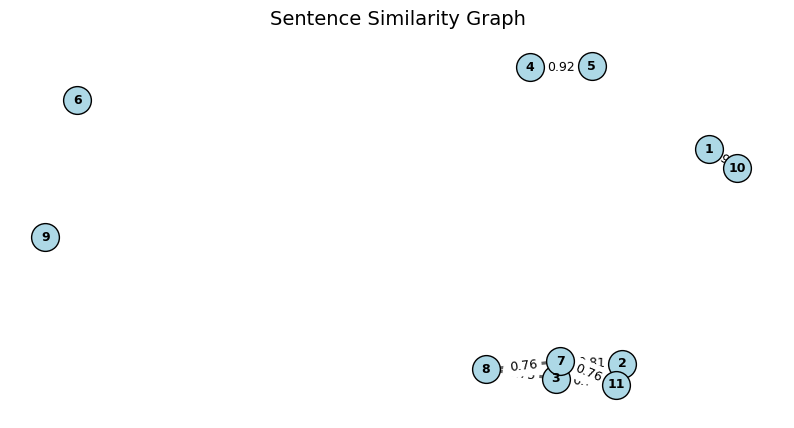

Questions after filtering:
1. who has been named as the cricketer of the year in the icc annual awards
2. which player highest numbers of runs in ipl history
3. which indian captain has won the maximum matches against sri lanka
4. who has been wisdens leading cricketer in the world for 2016
5. who scored most runs in t20 for india
6. who is the vice captain of india 2017


In [80]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(ent_clusters, entity_questions_embeddings)

# 4. Structure Data & Generate Counter Answers:

**Dataset Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answer type': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Reasoning path 1':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ],
    'Reasoning path 2':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ]
    'Distractor paragraphs': []
}
```

In [433]:
from knowledge_maze.create_dataset.create_data import process_data_to_list
structured_entities = await process_data_to_list(entity_reasoning_chains[:100], 'Wikipedia Entity')
structured_numericals = await process_data_to_list(numerical_reasoning_chains[:50], 'Numerical')
structured_dates = await process_data_to_list(date_reasoning_chains[:50], 'Date & Time')
# Merge all data:
knowledge_maze_qa = list(np.concatenate([structured_entities, structured_numericals, structured_dates]))
# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_qa.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(knowledge_maze_qa, out_file)

100%|██████████████████████████████████████████████████████████████████████████████████| 50/50 [00:02<00:00, 19.16it/s]


In [ ]:
# Load from saved dataset:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_qa.json")

# 5. Generate Paragraphs:

In [404]:
from knowledge_maze.create_dataset.create_data import create_paragraphs

knowledge_maze_paragraphs = await create_paragraphs(knowledge_maze_qa)

# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_paragraphs.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(knowledge_maze_paragraphs, out_file)

Usage cost: 0.0354$ (Estimated: 0.04$): 100%|████████████████████████████████████████| 370/370 [00:17<00:00, 21.60it/s]


In [ ]:
# Load from saved dataset:
knowledge_maze_paragraphs = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_paragraphs.json")

# TESTING

In [589]:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")
total_samples = tqa_dataset + nq_dataset + sqd_dataset

In [694]:
sntence_1 = 'Question: what is the tallest building in the northern hemisphere? Answer: Burj Khalifa'
sntence_2 = 'Burj Khalifa is the tallest building in the northern hemisphere'
type1 = nlp(sntence_1)
type2 = nlp(sntence_2)

In [703]:
print(type1.ents[0].label_)
print(type2.ents[0].label_)

PERSON
FAC


In [617]:
import random
import torch
aug_ques = []
for sample in total_samples: #random.choices(total_samples, k=5000):
    question_words = ["What", "Who", "When", "Where", "How", "Which"]
    match_count = sum(1 for word in question_words if word.lower() in sample['Question'].lower())
    # Check if exactly one question word is present
    if match_count == 1:
        aug_ques.append({"Question": sample['Question'], "Answer": sample['Answer']})

clust_aug_ques = cluster_wiki_entities(aug_ques)

filt_filt_ques = []
for answer, questions in clust_aug_ques.items():
    for question in questions:
        filt_filt_ques.append(f"Question: {question} Answer: {answer}")

# Load spaCy's Named Entity Recognizer:
# Force GPU usage if available:
if torch.cuda.is_available():
    spacy.require_gpu()
else:
    print("Notice: GPU not available, running on CPU.")
nlp = spacy.load("en_core_web_trf")
extracted_entities_aug = []
for doc in tqdm(nlp.pipe(filt_filt_ques, batch_size=1024), total=len(filt_filt_ques), desc="Extracting Entities"):
    extracted_entities_aug.append([(ent.text, ent.label_) for ent in doc.ents])
data_testest = []
for name, ent in zip(filt_filt_ques, extracted_entities_aug):
    if len(ent) > 0:
        if name.split(' Answer: ')[-1] == ent[-1][0]:
            data_testest.append(
                {
                    "Question": name.split(' Answer: ')[0],
                    "Answer": name.split(' Answer: ')[-1],
                    "Type": ent[-1]
                }
            )
            # print(f"{name.split(' Answer: ')[0]} --> {ent[-1]}")

Extracting Entities: 100%|████████████████████████████████████████████████████| 111842/111842 [06:12<00:00, 300.02it/s]


AttributeError: 'dict' object has no attribute 'split'

In [618]:
data_testest = []
for name, ent in zip(filt_filt_ques, extracted_entities_aug):
    if len(ent) > 0:
        if name.split(' Answer: ')[-1] == ent[-1][0]:
            data_testest.append(
                {
                    "Question": name.split(' Answer: ')[0],
                    "Answer": name.split(' Answer: ')[-1],
                    "Type": ent[-1]
                }
            )
            # print(f"{name.split(' Answer: ')[0]} --> {ent[-1]}")

In [619]:
from collections import defaultdict

def group_by_answer_and_type(data):
    """
    Groups questions based on the same answer and type, combining questions into a list.

    Args:
        data (list[dict]): List of dictionaries with keys "Question", "Answer", and "Type".

    Returns:
        list[dict]: List of grouped dictionaries with the same structure but "Question" as a list.
    """
    grouped_data = defaultdict(lambda: {"Questions": [], "Answer": None, "Type": None})

    for item in data:
        key = (item["Answer"], item["Type"])
        grouped_data[key]["Questions"].append(item["Question"])
        grouped_data[key]["Answer"] = item["Answer"]
        grouped_data[key]["Type"] = item["Type"]

    # Convert defaultdict to a standard list of dictionaries
    result = {}
    for grouped_item in grouped_data.values():
        result[grouped_item["Answer"]] = grouped_item["Questions"]
    # result = [
    #     {"Question": grouped_item["Questions"], "Answer": grouped_item["Answer"], "Type": grouped_item["Type"]}
    #     for grouped_item in grouped_data.values()
    # ]

    return result

In [625]:
grouped_data_testest = group_by_answer_and_type(data_testest)
filt_grouped_data_testest = {}
for answer, questions in grouped_data_testest.items():
    if len(questions) > 1:
        filt_grouped_data_testest[answer] = questions

filt_grouped_data_testest

{'Cyclops': ['Question: In Greek mythology, what is the name for a one-eyed giant?',
  'Question: What creature from Greek mythology has a single eye on the center of its forehead?',
  'Question: In Greek mythology, what sort of creature was Polyphemus?'],
 'Thurgood Marshall': ['Question: Who was the first black Supreme Court justice?',
  'Question: President Lyndon B. Johnson nominated the first African American judge to the US Supreme Court. Who was it?',
  'Question: who was the first african american to serve on the supreme court',
  'Question: who led the team that challenged the separate but equal ruling',
  'Question: who was the first african american supreme court justice',
  'Question: who was the first african american appointed to supreme court'],
 'Kerry': ['Question: Of which Irish county is Tralee the county town?',
  'Question: In which Irish county is Dingle Bay'],
 '2256': ['Question: when does the star trek discovery take place',
  'Question: where does star trek di

In [627]:
test_reasoning_chains = await create_paths(filt_grouped_data_testest)

Generating question embeddings: 100%|██████████████████████████████████████████████████| 39/39 [02:05<00:00,  3.22s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 10240/10240 [00:09<00:00, 1028.43it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████| 10240/10240 [00:00<00:00, 696884.25it/s]


In [628]:
structured_testtest = await process_data_to_list(test_reasoning_chains[:100], 'Wikipedia Entity')

Usage cost: 0.0032$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 75/75 [00:05<00:00, 13.81it/s]


In [661]:
from knowledge_maze.create_dataset.data_annotation import display_qa_sample
display_qa_sample(random.choice(structured_testtest))

ID: 11e3ccff-9b08-4702-b431-5e5f71604717
Type: Wikipedia Entity
Question: Question: "The ""Missouri Compromise"" allowed which state to join the USA in 1820 to
          balance the admission of Missouri?"
Original answer from dataset: None

Answers:
- Maine (Memory answer)
- Vermont (Counter answer 1)
- New Hampshire (Counter answer 2)
- Massachusetts (Distractor answer)

Sub-questions path 1:
 1. Question: "The ""Missouri Compromise"" allowed which state to join the USA in 1820 to
    balance the admission of Missouri?" --> None
 2. Question: In what U.S. state was Stephen King born? --> None
 3. Question: The town of Purgatory is in which US state? --> None

Sub-questions path 2:
 1. Question: "The ""Missouri Compromise"" allowed which state to join the USA in 1820 to
    balance the admission of Missouri?" --> None
 2. Question: The northernmost USA state on the eastern seaboard lies partly north of its
    neighbouring Canadian territory. Which is the state? --> None
 3. Question:

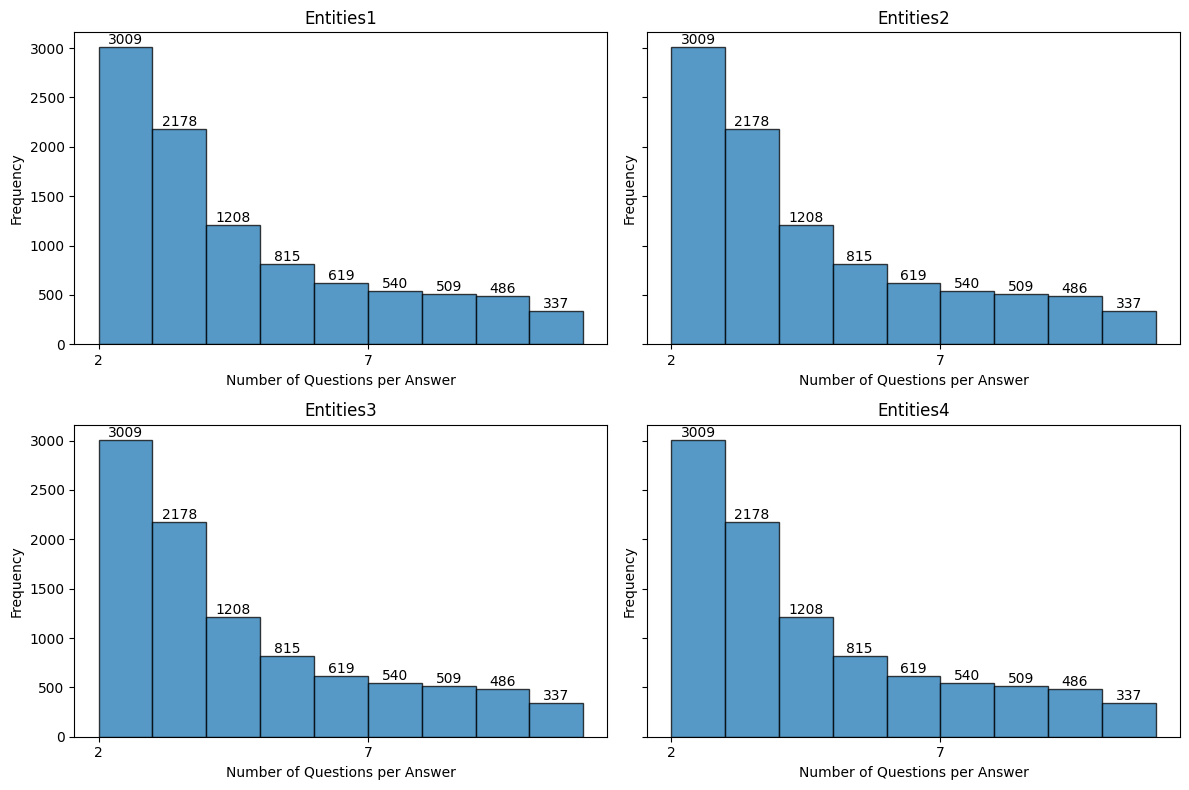

In [649]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution

lenths_testest = [len(sample["Questions"]) for sample in test_reasoning_chains]
plot_clusters_distribution({
    'Entities1': test_reasoning_chains,
    'Entities2': test_reasoning_chains,
    'Entities3': test_reasoning_chains,
    'Entities4': test_reasoning_chains,
})

In [692]:
list_of_answers = list(set([sample['Answer'] for sample in data_testest]))[400:700] # ['British', 'French', 'American']
for answer in list_of_answers:
    sample_answer_types = []
    for sample in data_testest:
        if sample['Answer'] == answer:
            sample_answer_types.append(sample['Type'][1])
    if len(list(set(sample_answer_types))) > 1:
        print('=' * 100)
        print(f"{answer}: {list(set(sample_answer_types))}")
        for sample in data_testest:
            if sample['Answer']== answer:
                print(f"{sample['Question']} --> {sample['Answer']} ({sample['Type'][1]})")

Parthenon: ['FAC', 'PERSON']
Question: Of which famous building was Ictinos the architect? --> Parthenon (FAC)
Question: What is the name of the temple on the Athenian Acropolis? --> Parthenon (FAC)
Question: The Elgin Marbles, currently in the British Museum, came from which building? --> Parthenon (FAC)
Question: Killikrates and Iktinos were the architects of which building completed on the 5th century BC? --> Parthenon (PERSON)
Burj Khalifa: ['FAC', 'PERSON']
Question: Name the Dubai tower officially opened in 2010 which is now the world's tallest building. --> Burj Khalifa (PERSON)
Question: what's the tallest building in the world right now --> Burj Khalifa (PERSON)
Question: what are the 3 tallest buildings in the world --> Burj Khalifa (PERSON)
Question: what is the name of the tallest building in the world located in dubai --> Burj Khalifa (FAC)
Question: what is the tallest building in the northern hemisphere --> Burj Khalifa (PERSON)
Santander: ['ORG', 'GPE']
Question: What B

In [691]:
types_examples = []
for sample in data_testest:
    if sample['Type'][1] == 'FAC':
        types_examples.append(sample['Answer'])
        if sample['Answer']== "Munich":
            print(f"{sample['Question']} --> {sample['Answer']}")
print(list(set(types_examples)))

Question: Where did Queen record their 1982 album?  --> Munich
['Gloucester Cathedral', 'Nationals Park', 'Eighth', 'Royal Oak', 'Number One Observatory Circle', 'Quality Street', 'M4', 'The Crucible', 'Square', 'Kew Gardens', 'Longleat', 'Benghazi', 'Skye', 'Dolby Theatre', 'Speedway', 'Vatican City', 'Hanover', 'Cherbourg-Octeville', 'Monaco', 'Arc de Triomphe', 'Palace of Westminster', 'Buckingham Palace', 'Vine Street', 'Central', 'Central Park', 'Yankee Stadium', 'Yellowstone National Park', 'East High School', 'Berkeley', 'AT&T Stadium', 'Lexington', 'Palace of Versailles', 'Welland Canal', 'Bastille', 'Dunedin Stadium', 'Augusta', 'Sunset Boulevard', 'Shangri-La', 'Castle Howard', 'Piccadilly', 'St. Moritz', 'Wembley Stadium', 'Kensington Gardens', 'Port of Spain', 'Gettysburg', 'Bridge', 'Shamrock', "St. John's", 'Balmoral Castle', 'Louvre', 'Lodge', 'Charles de Gaulle Airport', 'Queenstown', 'Telescope', 'Panama Canal', 'Hogwarts', 'Riverside Drive', 'Bramall Lane', 'Vatican I

In [606]:
def count_how_many(dataset):
    person_answers = []
    """
    Counts how many questions contain exactly one of the specified question words.

    Args:
        dataset (list[dict]): Dataset containing questions.

    Returns:
        int: Number of questions containing exactly one question word.
    """
    question_words = ["What", "Who", "When", "Where", "How", "Which"]
    count_question_words = 0

    # Iterate over the dataset
    for sample in dataset:
        # Count how many question words appear in the question
        match_count = sum(1 for word in question_words if word.lower() in sample['Question'].lower())
        # Check if exactly one question word is present
        if match_count == 1:
            count_question_words += 1
            # if "where" in sample['Question'].lower():
            #    print(f"{sample['Question']} --> {sample['Answer']}")
            person_answers.append(sample['Answer'])

    return count_question_words, person_answers


# Print the count and the total number of samples
rel_count = count_how_many(tqa_dataset)[0] + count_how_many(nq_dataset)[0] + count_how_many(sqd_dataset)[0]
tot_count = len(sqd_dataset)+ len(nq_dataset) + len(sqd_dataset)
print(f"{rel_count} / {tot_count} ({100 * (rel_count / tot_count):.1f}%)")

245854 / 280568 (87.6%)


In [607]:
person_answers = count_how_many(tqa_dataset)[1] + count_how_many(nq_dataset)[1] + count_how_many(sqd_dataset)[1]

In [608]:
import matplotlib.pyplot as plt
from collections import Counter

def create_name_frequency_histogram_and_extract(names):
    """
    Creates a histogram of name frequencies and returns a set of names that appear more than 2 times.

    Args:
        names (list[str]): A list of names.

    Returns:
        set: A set of names that appear more than 2 times.
    """
    # Count the frequency of each name in the list
    name_counts = Counter(names)
    
    # Count how many names have each frequency (range 0-100)
    frequency_counts = Counter(name_counts.values())
    
    # Prepare data for the histogram (x-axis: frequency, y-axis: count of names with that frequency)
    x_values = range(2, 25)  # Frequencies from 1 to 100
    y_values = [frequency_counts.get(i, 0) for i in x_values]  # Get the count for each frequency, default to 0
    
    # Plot the histogram
    plt.figure(figsize=(10, 6))
    plt.bar(x_values, y_values, color='skyblue', edgecolor='black')
    plt.title('Name Frequency Histogram', fontsize=16)
    plt.xlabel('Frequency of Names', fontsize=14)
    plt.ylabel('Number of Names', fontsize=14)
    plt.xticks(range(2, 25, 5))  # Adjust x-axis ticks for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
    
    # Extract names that appear more than 2 times
    names_more_than_2 = {name for name, count in name_counts.items() if count > 2}
    
    return names_more_than_2

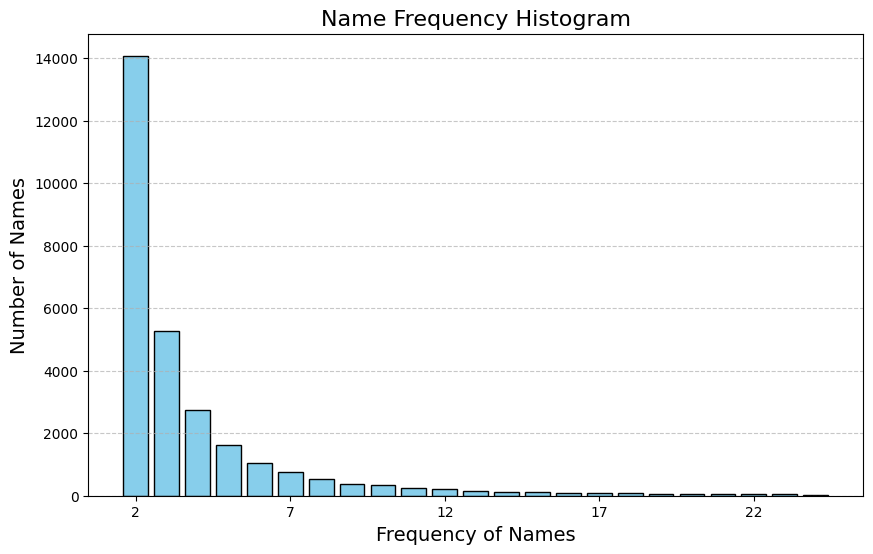

In [609]:
filt_names = create_name_frequency_histogram_and_extract(person_answers)

In [610]:
import spacy

# Load spaCy's Named Entity Recognizer:
nlp = spacy.load("en_core_web_trf")
extracted_entities = []
for doc in tqdm(nlp.pipe(filt_names, batch_size=1024), total=len(filt_names), desc="Extracting Entities"):
    extracted_entities.append([(ent.text, ent.label_) for ent in doc.ents])
for name, ent in zip(filt_names, extracted_entities):
    print(f"{name} --> {ent}")

Extracting Entities: 100%|██████████████████████████████████████████████████████| 14667/14667 [02:09<00:00, 113.68it/s]

horses --> []
James A. Garfield --> [('James A. Garfield', 'PERSON')]
Matthew David Lewis --> [('Matthew David Lewis', 'PERSON')]
Battlestar Galactica --> [('Battlestar Galactica', 'WORK_OF_ART')]
the fourth season --> [('fourth', 'ORDINAL')]
KAZZ (AM) --> [('KAZZ', 'PERSON')]
Jonah Hill --> [('Jonah Hill', 'PERSON')]
Anthony Newley --> [('Anthony Newley', 'PERSON')]
Zhu Yuanzhang --> [('Zhu Yuanzhang', 'PERSON')]
1990s --> [('1990s', 'DATE')]
Eric Morecambe --> [('Eric Morecambe', 'PERSON')]
Terry Gilliam --> [('Terry Gilliam', 'PERSON')]
Jean Sibelius --> [('Jean Sibelius', 'PERSON')]
East India Company --> [('East India Company', 'GPE')]
Sevastopol --> [('Sevastopol', 'GPE')]
Cyclops --> []
Thurgood Marshall --> [('Thurgood Marshall', 'PERSON')]
Mumford & Sons --> [('Mumford & Sons', 'ORG')]
Jonathan Breck --> [('Jonathan Breck', 'PERSON')]
Sean McVay --> [('Sean McVay', 'PERSON')]
Kerry --> [('Kerry', 'PERSON')]
Ronald N. Perlman --> [('Ronald N. Perlman', 'PERSON')]
K.K. Venugopal

In [611]:
for name, ent in zip(filt_names, extracted_entities):
    if any(char.isupper() for char in name):
        print(f"{name} --> {ent}")

James A. Garfield --> [('James A. Garfield', 'PERSON')]
Matthew David Lewis --> [('Matthew David Lewis', 'PERSON')]
Battlestar Galactica --> [('Battlestar Galactica', 'WORK_OF_ART')]
KAZZ (AM) --> [('KAZZ', 'PERSON')]
Jonah Hill --> [('Jonah Hill', 'PERSON')]
Anthony Newley --> [('Anthony Newley', 'PERSON')]
Zhu Yuanzhang --> [('Zhu Yuanzhang', 'PERSON')]
Eric Morecambe --> [('Eric Morecambe', 'PERSON')]
Terry Gilliam --> [('Terry Gilliam', 'PERSON')]
Jean Sibelius --> [('Jean Sibelius', 'PERSON')]
East India Company --> [('East India Company', 'GPE')]
Sevastopol --> [('Sevastopol', 'GPE')]
Cyclops --> []
Thurgood Marshall --> [('Thurgood Marshall', 'PERSON')]
Mumford & Sons --> [('Mumford & Sons', 'ORG')]
Jonathan Breck --> [('Jonathan Breck', 'PERSON')]
Sean McVay --> [('Sean McVay', 'PERSON')]
Kerry --> [('Kerry', 'PERSON')]
Ronald N. Perlman --> [('Ronald N. Perlman', 'PERSON')]
K.K. Venugopal --> [('K.K. Venugopal', 'PERSON')]
Hawthorn --> [('Hawthorn', 'PERSON')]
X --> []
John St

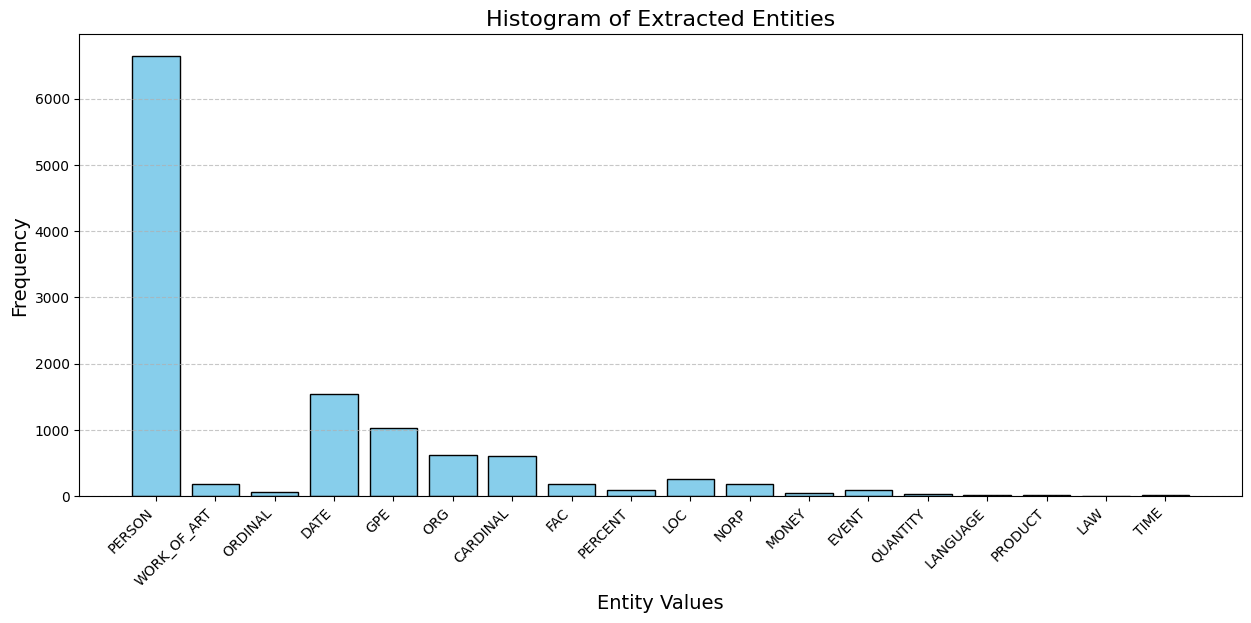

In [613]:
import matplotlib.pyplot as plt
from collections import Counter

# Prepare your data
data = [ent[0][1] for ent in extracted_entities if len(ent) >= 1]

# Count the frequencies of the data
frequency_counts = Counter(data)

# Extract the unique labels and their frequencies
x_labels = list(frequency_counts.keys())
y_values = list(frequency_counts.values())

# Create the histogram
plt.figure(figsize=(15, 6))
plt.bar(x_labels, y_values, width=0.8, color='skyblue', edgecolor='black')

# Customize x-axis labels to make them diagonal and center them
plt.xticks(rotation=45, ha='right', fontsize=10)  # Rotate labels diagonally
plt.gca().set_xticks(range(len(x_labels)))  # Ensure labels align with their bars
plt.gca().set_xticklabels(x_labels)  # Set custom x-axis labels

# Add labels, title, and grid
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title('Histogram of Extracted Entities', fontsize=16)
plt.xlabel('Entity Values', fontsize=14)
plt.ylabel('Frequency', fontsize=14)

# Show the plot
plt.show()